In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from category_encoders import OneHotEncoder

In [2]:
from wrangle import clean_files

df = clean_files("../data/raw/buenos-aires-real-estate-*.csv")

target_col = "price_aprox_usd"
feature_cols = [col for col in df.columns if col != target_col]

X = df[feature_cols]
y = df[target_col]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Feature columns: {X.columns.tolist()}")
print(f"Unique neighborhoods: {X['neighborhood'].nunique()}")

Features shape: (6247, 4)
Target shape: (6247,)
Feature columns: ['surface_covered_in_m2', 'lat', 'lon', 'neighborhood']
Unique neighborhoods: 56


In [3]:
X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set: {X_train_3.shape[0]} samples")
print(f"Test set: {X_test_3.shape[0]} samples")

Training set: 4997 samples
Test set: 1250 samples


In [4]:
model_ridge_3 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    Ridge(alpha=1.0)
)

model_ridge_3

/workspaces/Buenos_Aires_price_prediction_using_Linear_Regression/.venv/lib/python3.12/site-packages/sklearn/externals/_numpydoc/docscrape.py:420: UserWarning: Unknown section Example
  self[section] = content


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,use_cat_names,True
,verbose,0
,cols,None
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'


In [5]:
model_ridge_3.fit(X_train_3, y_train_3)

y_pred_ridge_train = model_ridge_3.predict(X_train_3)
y_pred_ridge_test = model_ridge_3.predict(X_test_3)

rmse_ridge_train = root_mean_squared_error(y_train_3, y_pred_ridge_train)
rmse_ridge_test = root_mean_squared_error(y_test_3, y_pred_ridge_test)

print(f"Ridge Training RMSE: ${rmse_ridge_train:,.2f}")
print(f"Ridge Test RMSE: ${rmse_ridge_test:,.2f}")
print(f"Ridge Test MAE: ${mean_absolute_error(y_test_3, y_pred_ridge_test):,.2f}")
print(f"Ridge Test R²: {r2_score(y_test_3, y_pred_ridge_test):.4f}")

Ridge Training RMSE: $33,174.63
Ridge Test RMSE: $36,971.20
Ridge Test MAE: $26,441.06
Ridge Test R²: 0.6330


In [6]:
encoded = model_ridge_3[:-1].transform(X_train_3)
print(encoded.shape)
print(model_ridge_3[0].get_feature_names_out()[:8])

(4997, 59)
['surface_covered_in_m2' 'lat' 'lon' 'neighborhood_Constitución'
 'neighborhood_Caballito' 'neighborhood_Flores' 'neighborhood_Belgrano'
 'neighborhood_Recoleta']


In [7]:
model_lasso_3 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    Lasso(alpha=100, max_iter=100000)
)

model_lasso_3.fit(X_train_3, y_train_3)

y_pred_lasso_train = model_lasso_3.predict(X_train_3)
y_pred_lasso_test = model_lasso_3.predict(X_test_3)

rmse_lasso_train = root_mean_squared_error(y_train_3, y_pred_lasso_train)
rmse_lasso_test = root_mean_squared_error(y_test_3, y_pred_lasso_test)

print(f"Lasso Training RMSE: ${rmse_lasso_train:,.2f}")
print(f"Lasso Test RMSE: ${rmse_lasso_test:,.2f}")
print(f"Lasso Test MAE: ${mean_absolute_error(y_test_3, y_pred_lasso_test):,.2f}")
print(f"Lasso Test R²: {r2_score(y_test_3, y_pred_lasso_test):.4f}")

lasso_coefs = pd.Series(
    model_lasso_3[-1].coef_,
    index=model_lasso_3[0].get_feature_names_out(),
)
print(f"Non-zero coefficients: {(lasso_coefs != 0).sum()} of {len(lasso_coefs)}")
print(f"Zeroed-out features: {(lasso_coefs == 0).sum()}")

Lasso Training RMSE: $33,195.81
Lasso Test RMSE: $36,916.38
Lasso Test MAE: $26,329.42
Lasso Test R²: 0.6341
Non-zero coefficients: 51 of 59
Zeroed-out features: 8


In [8]:
print(lasso_coefs[lasso_coefs == 0].index.tolist())

['neighborhood_Saavedra', 'neighborhood_Villa del Parque', 'neighborhood_Abasto', 'neighborhood_Villa General Mitre', 'neighborhood_Villa Real', 'neighborhood_Parque Avellaneda', 'neighborhood_Chacarita', 'neighborhood_']


In [9]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000]
ridge_results = []

for a in alphas:
    model = make_pipeline(
        OneHotEncoder(use_cat_names=True),
        StandardScaler(),
        Ridge(alpha=a)
    )
    model.fit(X_train_3, y_train_3)

    rmse_train = root_mean_squared_error(y_train_3, model.predict(X_train_3))
    rmse_test = root_mean_squared_error(y_test_3, model.predict(X_test_3))

    ridge_results.append({"alpha": a, "rmse_train": rmse_train, "rmse_test": rmse_test})

df_ridge_results = pd.DataFrame(ridge_results)
print(df_ridge_results)

         alpha    rmse_train     rmse_test
0        0.001  33174.627686  36971.857963
1        0.010  33174.627686  36971.852000
2        0.100  33174.627709  36971.792414
3        1.000  33174.630059  36971.200624
4       10.000  33174.857341  36965.674667
5      100.000  33192.565525  36939.565183
6     1000.000  34066.133694  37638.241670
7    10000.000  45363.746872  48137.509999
8   100000.000  56602.479662  58906.292083
9  1000000.000  58590.146991  60828.658590


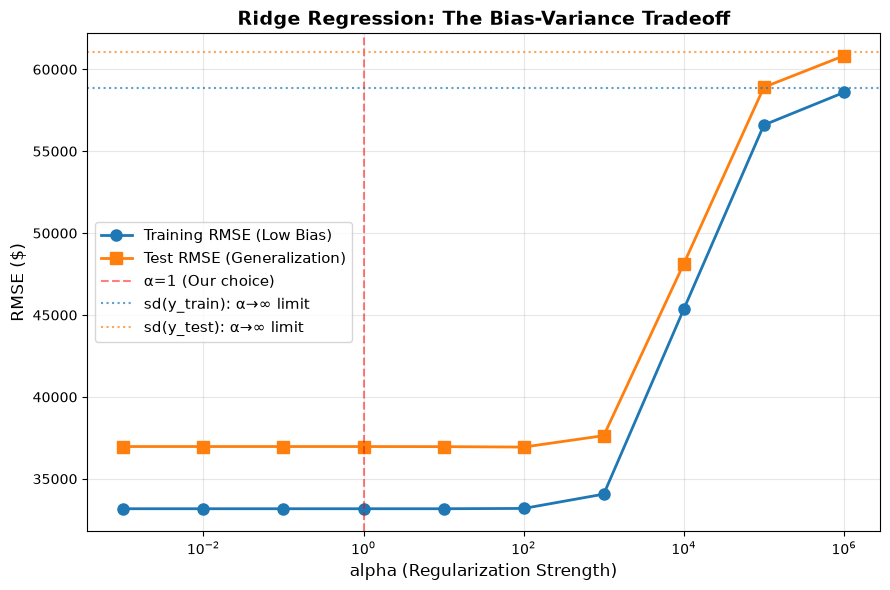

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(df_ridge_results["alpha"], df_ridge_results["rmse_train"],
        marker='o', linewidth=2, markersize=8, label="Training RMSE (Low Bias)")
ax.plot(df_ridge_results["alpha"], df_ridge_results["rmse_test"],
        marker='s', linewidth=2, markersize=8, label="Test RMSE (Generalization)")
ax.axvline(x=1, color='red', linestyle='--', alpha=0.5, label="α=1 (Our choice)")

ax.axhline(y_train_3.std(), color='C0', linestyle=':', alpha=0.7, label="sd(y_train): α→∞ limit")
ax.axhline(y_test_3.std(), color='C1', linestyle=':', alpha=0.7, label="sd(y_test): α→∞ limit")
ax.set_xlabel("alpha (Regularization Strength)", fontsize=12)
ax.set_ylabel("RMSE ($)", fontsize=12)
ax.set_xscale("log")
ax.set_title("Ridge Regression: The Bias-Variance Tradeoff", fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig("../reports/figures/ridge_alpha_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
lasso_results = []
alphas_lasso = [0.1, 1, 10, 100, 1000]

for a in alphas_lasso:
    model = make_pipeline(
        OneHotEncoder(use_cat_names=True),
        StandardScaler(),
        Lasso(alpha=a, max_iter=100000)
    )
    model.fit(X_train_3, y_train_3)

    rmse_train = root_mean_squared_error(y_train_3, model.predict(X_train_3))
    rmse_test = root_mean_squared_error(y_test_3, model.predict(X_test_3))
    non_zero_features = (model.named_steps["lasso"].coef_ != 0).sum()

    lasso_results.append({
        "alpha": a,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
        "non_zero_features": non_zero_features
    })

df_lasso_results = pd.DataFrame(lasso_results)
print(df_lasso_results)

    alpha    rmse_train     rmse_test  non_zero_features
0     0.1  33174.627717  36971.759755                 58
1     1.0  33174.630810  36970.863141                 57
2    10.0  33174.940327  36962.125344                 57
3   100.0  33195.812467  36916.381945                 51
4  1000.0  33784.712145  37290.560830                 29


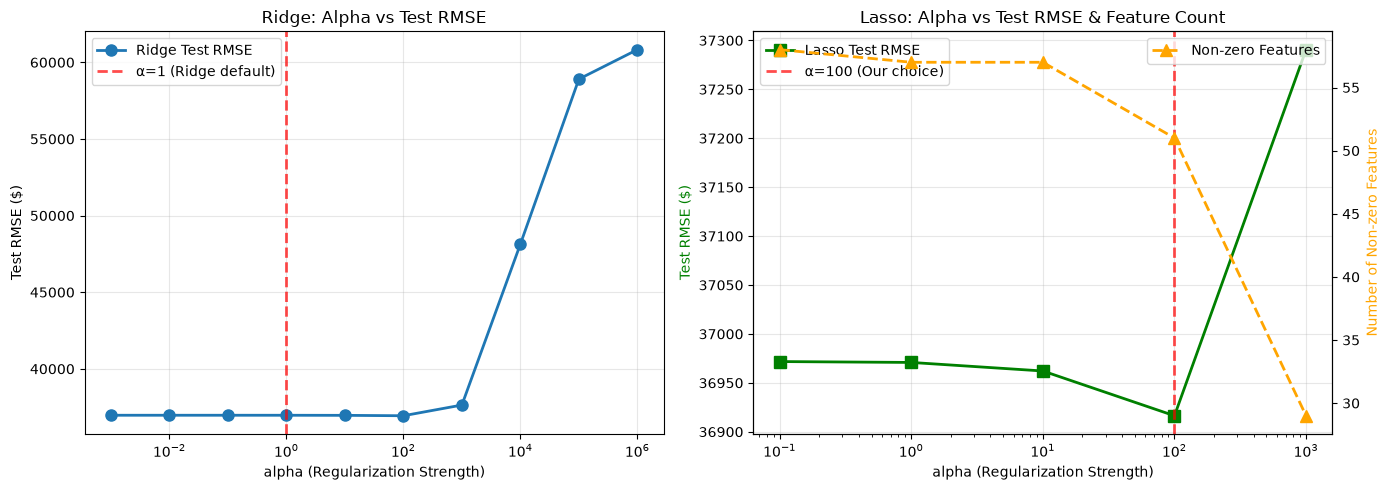

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(df_ridge_results["alpha"], df_ridge_results["rmse_test"],
         marker='o', linewidth=2, markersize=8, label="Ridge Test RMSE")
ax1.axvline(x=1, color='red', linestyle='--', alpha=0.7, linewidth=2, label="α=1 (Ridge default)")
ax1.set_xlabel("alpha (Regularization Strength)")
ax1.set_ylabel("Test RMSE ($)")
ax1.set_xscale("log")
ax1.set_title("Ridge: Alpha vs Test RMSE")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2_twin = ax2.twinx()
ax2.plot(df_lasso_results["alpha"], df_lasso_results["rmse_test"],
         marker='s', linewidth=2, markersize=8, color='green', label="Lasso Test RMSE")
ax2_twin.plot(df_lasso_results["alpha"], df_lasso_results["non_zero_features"],
              marker='^', linewidth=2, markersize=8, color='orange', linestyle='--', label="Non-zero Features")
ax2.axvline(x=100, color='red', linestyle='--', alpha=0.7, linewidth=2, label="α=100 (Our choice)")
ax2.set_xlabel("alpha (Regularization Strength)")
ax2.set_ylabel("Test RMSE ($)", color='green')
ax2_twin.set_ylabel("Number of Non-zero Features", color='orange')
ax2.set_xscale("log")
ax2.set_title("Lasso: Alpha vs Test RMSE & Feature Count")
ax2.legend(loc='upper left')
ax2_twin.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig("../reports/figures/alpha_sweeps.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
import warnings

for a in [0.1, 1, 10, 100, 1000]:
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        m = make_pipeline(OneHotEncoder(use_cat_names=True), StandardScaler(),
                          Lasso(alpha=a, max_iter=100000))
        m.fit(X_train_3, y_train_3)
    print(a, "did not converge" if w else "converged")

0.1 did not converge
1 did not converge
10 did not converge
100 did not converge
1000 did not converge


In [14]:
from sklearn.linear_model import RidgeCV, LassoCV

ridge_cv_model = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    RidgeCV(alphas=[0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000], cv=5)
)
ridge_cv_model.fit(X_train_3, y_train_3)

optimal_alpha_ridge = ridge_cv_model.named_steps["ridgecv"].alpha_
pred_ridge_cv = ridge_cv_model.predict(X_test_3)
print(f"RidgeCV selected alpha: {optimal_alpha_ridge}")
print(f"Ridge CV Test RMSE: ${root_mean_squared_error(y_test_3, pred_ridge_cv):,.2f}")
print(f"Ridge CV Test MAE:  ${mean_absolute_error(y_test_3, pred_ridge_cv):,.2f}")
print(f"Ridge CV Test R²:   {r2_score(y_test_3, pred_ridge_cv):.4f}")

lasso_cv_model = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LassoCV(alphas=[0.1, 1, 10, 100, 1000], cv=5, max_iter=100000)
)
lasso_cv_model.fit(X_train_3, y_train_3)

optimal_alpha_lasso = lasso_cv_model.named_steps["lassocv"].alpha_
pred_lasso_cv = lasso_cv_model.predict(X_test_3)
print(f"\nLassoCV selected alpha: {optimal_alpha_lasso}")
print(f"Lasso CV Test RMSE: ${root_mean_squared_error(y_test_3, pred_lasso_cv):,.2f}")
print(f"Lasso CV Test MAE:  ${mean_absolute_error(y_test_3, pred_lasso_cv):,.2f}")
print(f"Lasso CV Test R²:   {r2_score(y_test_3, pred_lasso_cv):.4f}")
print(f"Non-zero features (Lasso CV): {(lasso_cv_model.named_steps['lassocv'].coef_ != 0).sum()}")

RidgeCV selected alpha: 10.0
Ridge CV Test RMSE: $36,965.67
Ridge CV Test MAE:  $26,429.46
Ridge CV Test R²:   0.6331

LassoCV selected alpha: 100.0
Lasso CV Test RMSE: $36,916.38
Lasso CV Test MAE:  $26,329.42
Lasso CV Test R²:   0.6341
Non-zero features (Lasso CV): 51


**Convergence check.** Refitting the scaled Lasso pipeline with `max_iter=100000` 
converged at every alpha in [0.1, 1, 10, 100, 1000]. Only alpha=0.1 needed more than 
10,000 iterations (10,751), which is why the earlier cap of 10,000 produced warnings. 
At alpha=0.1 the converged model keeps 58 of 59 features. At the CV-selected alpha=100 
the results are unchanged: test RMSE $36,916.38 with 51 non-zero features.

In [16]:
import pandas as pd

features = model_lasso_3[0].get_feature_names_out()
coefs = model_lasso_3[-1].coef_

feat_imp_3 = pd.Series(coefs, index=features).sort_values()

print("Total features:", len(feat_imp_3))
print("Non-zero:", (feat_imp_3 != 0).sum())
print("Zeroed:", (feat_imp_3 == 0).sum())
print()
print("Features Lasso zeroed:")
print(list(feat_imp_3[feat_imp_3 == 0].index))

Total features: 59
Non-zero: 51
Zeroed: 8

Features Lasso zeroed:
['neighborhood_Abasto', 'neighborhood_Saavedra', 'neighborhood_Villa del Parque', 'neighborhood_', 'neighborhood_Villa Real', 'neighborhood_Villa General Mitre', 'neighborhood_Chacarita', 'neighborhood_Parque Avellaneda']


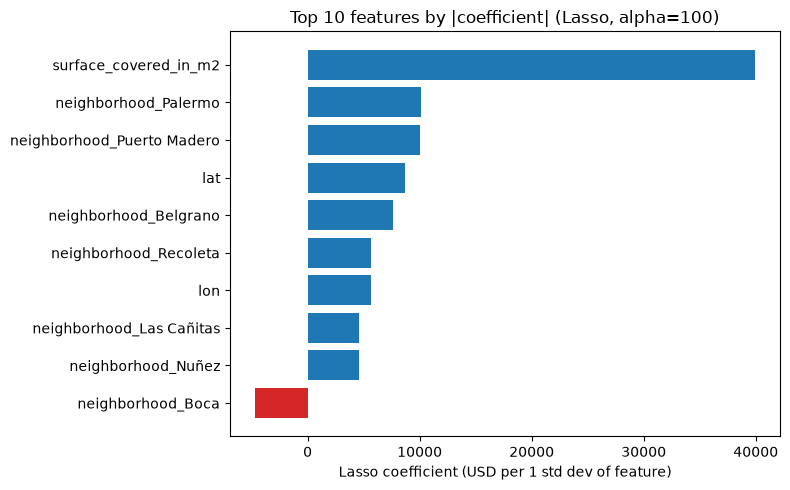

In [17]:
import matplotlib.pyplot as plt

top10 = feat_imp_3[feat_imp_3.abs().sort_values().tail(10).index].sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["tab:red" if v < 0 else "tab:blue" for v in top10]
ax.barh(top10.index, top10.values, color=colors)
ax.set_xlabel("Lasso coefficient (USD per 1 std dev of feature)")
ax.set_title("Top 10 features by |coefficient| (Lasso, alpha=100)")
plt.tight_layout()
plt.savefig("../reports/figures/lasso_top10_coefficients.png", dpi=150)
plt.show()

In [18]:
%whos DataFrame Series

Variable           Type         Data/Info
-----------------------------------------
X                  DataFrame    Shape: (6247, 4)
X_test_3           DataFrame    Shape: (1250, 4)
X_train_3          DataFrame    Shape: (4997, 4)
df                 DataFrame    Shape: (6247, 5)
df_lasso_results   DataFrame    Shape: (5, 4)
df_ridge_results   DataFrame    Shape: (10, 3)
feat_imp_3         Series       Shape: (59,)
lasso_coefs        Series       Shape: (59,)
top10              Series       Shape: (10,)
y                  Series       Shape: (6247,)
y_test_3           Series       Shape: (1250,)
y_train_3          Series       Shape: (4997,)


In [21]:
zeroed = [f.replace("neighborhood_", "", 1) for f in feat_imp_3[feat_imp_3 == 0].index]
counts = X_train_3["neighborhood"].value_counts(dropna=False)

print("Listings in train for each zeroed neighborhood:")
print(pd.Series({z: counts.get(z, 0) for z in zeroed}).sort_values())
print()
print("Unique neighborhoods in train:", X_train_3["neighborhood"].nunique(dropna=False))
print("Empty-string names:", (X_train_3["neighborhood"] == "").sum())
print("Missing names:", X_train_3["neighborhood"].isna().sum())

Listings in train for each zeroed neighborhood:
Villa Real               2
                         6
Parque Avellaneda       10
Abasto                  16
Villa General Mitre     18
Chacarita               34
Villa del Parque        86
Saavedra               134
dtype: int64

Unique neighborhoods in train: 56
Empty-string names: 6
Missing names: 0


In [19]:
hood = feat_imp_3[feat_imp_3.index.str.startswith("neighborhood_")]
hood = hood[hood != 0]

print("Top 5 positive neighborhoods:")
print(hood.sort_values(ascending=False).head(5).round(0))
print()
print("Top 5 negative neighborhoods:")
print(hood.sort_values().head(5).round(0))

Top 5 positive neighborhoods:
neighborhood_Palermo          10110.0
neighborhood_Puerto Madero    10039.0
neighborhood_Belgrano          7606.0
neighborhood_Recoleta          5690.0
neighborhood_Las Cañitas       4559.0
dtype: float64

Top 5 negative neighborhoods:
neighborhood_Boca           -4704.0
neighborhood_Balvanera      -4529.0
neighborhood_Once           -4028.0
neighborhood_Congreso       -2421.0
neighborhood_Villa Lugano   -2332.0
dtype: float64


**Which neighborhoods move the price?** At alpha=100, Lasso keeps 51 of 59 features and zeroes 8, all of them neighborhoods. The largest positive neighborhood coefficients are Palermo (+$10,110), Puerto Madero (+$10,039), Belgrano (+$7,606), Recoleta (+$5,690) and Las Cañitas (+$4,559). The largest negative are Boca (-$4,704), Balvanera (-$4,529), Once (-$4,028), Congreso (-$2,421) and Villa Lugano (-$2,332). These effects are on top of surface, lat and lon, and the coefficients are in standardized units (USD per 1 std dev of the feature), so they are not the dollar premium for living in a neighborhood. A zeroed neighborhood is not "worthless": it means the model found it redundant given the other features.

In [20]:
scaler = model_lasso_3[1]
real = pd.Series(
    model_lasso_3[-1].coef_ / scaler.scale_,
    index=model_lasso_3[0].get_feature_names_out(),
)

print("Surface: $%.0f per extra m²" % real["surface_covered_in_m2"])
print()
hood_real = real[real.index.str.startswith("neighborhood_")]
hood_real = hood_real[hood_real != 0]
print("Top 5 positive (USD for being in the neighborhood):")
print(hood_real.sort_values(ascending=False).head(5).round(0))
print()
print("Top 5 negative:")
print(hood_real.sort_values().head(5).round(0))

Surface: $2219 per extra m²

Top 5 positive (USD for being in the neighborhood):
neighborhood_Puerto Madero    114081.0
neighborhood_Las Cañitas       70468.0
neighborhood_Recoleta          38607.0
neighborhood_Palermo           33873.0
neighborhood_Belgrano          27038.0
dtype: float64

Top 5 negative:
neighborhood_Villa Soldati   -46624.0
neighborhood_Villa Lugano    -40049.0
neighborhood_Boca            -39208.0
neighborhood_Once            -35284.0
neighborhood_Pompeya         -29993.0
dtype: float64


**Surface in real units.** Dividing the Lasso coefficient by the scaler's standard deviation gives about $2,219 per extra m² (alpha=100, all features), versus $2,275 per m² for the size-only model in 2.2. Adding location changes the size effect by only about 2.5%, so the improvement from R² 0.45 to 0.63 comes mostly from the neighborhood and lat/lon features explaining price variation that size alone cannot, not from a different size slope.

In [22]:
names = (list(hood_real.sort_values(ascending=False).head(5).index)
         + list(hood_real.sort_values().head(5).index))
counts = X_train_3["neighborhood"].value_counts()

check = pd.DataFrame({
    "USD effect": hood_real[names].round(0),
    "train listings": [counts.get(n.replace("neighborhood_", "", 1), 0) for n in names],
})
print(check)

                            USD effect  train listings
neighborhood_Puerto Madero    114081.0              39
neighborhood_Las Cañitas       70468.0              21
neighborhood_Recoleta          38607.0             111
neighborhood_Palermo           33873.0             494
neighborhood_Belgrano          27038.0             433
neighborhood_Villa Soldati    -46624.0               4
neighborhood_Villa Lugano     -40049.0              17
neighborhood_Boca             -39208.0              73
neighborhood_Once             -35284.0              66
neighborhood_Pompeya          -29993.0               4


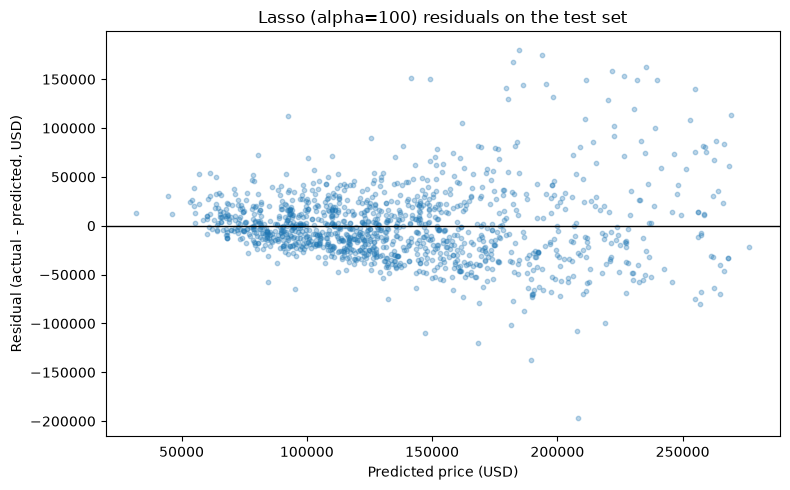

Mean residual: $-429
Residual std:  $36929
Largest over-prediction:  $-196849
Largest under-prediction: $180152


In [23]:
import matplotlib.pyplot as plt

pred = model_lasso_3.predict(X_test_3)
resid = y_test_3 - pred

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(pred, resid, alpha=0.3, s=10)
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Predicted price (USD)")
ax.set_ylabel("Residual (actual - predicted, USD)")
ax.set_title("Lasso (alpha=100) residuals on the test set")
plt.tight_layout()
plt.savefig("../reports/figures/lasso_residuals.png", dpi=150)
plt.show()

print("Mean residual: $%.0f" % resid.mean())
print("Residual std:  $%.0f" % resid.std())
print("Largest over-prediction:  $%.0f" % resid.min())
print("Largest under-prediction: $%.0f" % resid.max())

**Residuals.** On the test set the Lasso (alpha=100) residuals have a mean of -$429 and a standard deviation of $36,929, so the model is unbiased on average. Predictions now reach about $275k (up from about $240k in 2.2), but the funnel remains: below about $150k predicted, residuals mostly stay within ±$50k, while above $175k they spread to ±$150k or more. The largest errors are an over-prediction of $196,849 and an under-prediction of $180,152. The model is much less reliable for expensive listings, which points to a log-transformed target or a nonlinear model as the next step.

In [24]:
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

rows = []
for name, m in [("Ridge (alpha=10, CV)", ridge_cv_model), ("Lasso (alpha=100, CV)", lasso_cv_model)]:
    p = m.predict(X_test_3)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_3, p),
        "RMSE": np.sqrt(np.mean((y_test_3 - p) ** 2)),
        "R2": r2_score(y_test_3, p),
    })

print(pd.DataFrame(rows).round(4).to_string(index=False))

                Model        MAE       RMSE     R2
 Ridge (alpha=10, CV) 26429.4589 36965.6747 0.6331
Lasso (alpha=100, CV) 26329.4198 36916.3819 0.6341


In [25]:
from sklearn.metrics import root_mean_squared_error

rows = []
for name, m in [("Ridge (alpha=1)", model_ridge_3), ("Lasso (alpha=100)", model_lasso_3)]:
    rows.append({
        "Model": name,
        "RMSE_train": root_mean_squared_error(y_train_3, m.predict(X_train_3)),
        "RMSE_test": root_mean_squared_error(y_test_3, m.predict(X_test_3)),
    })
df_comparison = pd.DataFrame(rows)
df_comparison["Non-zero_features"] = ["All (59)", int((feat_imp_3 != 0).sum())]
print(df_comparison.round(0).to_string(index=False))

            Model  RMSE_train  RMSE_test Non-zero_features
  Ridge (alpha=1)     33175.0    36971.0          All (59)
Lasso (alpha=100)     33196.0    36916.0                51


**Ridge vs Lasso.** With CV-selected alphas, Ridge (alpha=10) and Lasso (alpha=100) are effectively tied on the test set: RMSE $36,966 vs $36,916, MAE $26,429 vs $26,329, R² 0.6331 vs 0.6341. The $49 RMSE gap is far smaller than the variation a different random split would produce, so neither model is more accurate. Lasso's advantage is parsimony: it reaches the same accuracy with 51 of 59 features, which makes it the easier model to interpret. Both models have the same ceiling, set by the linear form and the available features, not by overfitting.

## Discussion Questions

**1. Ridge vs Lasso.** Lasso fits the stated belief that only some neighborhoods matter, because it can zero the rest. In our data it zeroed 8 of 59 features (seven small or redundant neighborhoods and one blank-name category) and matched Ridge's accuracy. So Lasso was the better choice for interpretability, not for accuracy. Ridge was no worse in error terms.

**2. Pipeline order.** `OneHotEncoder` has to come first because `StandardScaler` only works on numbers, and the neighborhood column contains text. Scaling before encoding would either fail or scale a meaningless integer code for each neighborhood. One caveat: scaling the 0/1 dummies gives rare neighborhoods small standard deviations, so their standardized coefficients are not comparable to common ones. This is why the dollar effects for rare neighborhoods (for example Puerto Madero, 39 training listings) looked much larger than the standardized plot suggested.

**3. Alpha tuning.** If training RMSE is much lower than test RMSE, the model has high variance, so increase alpha to shrink the coefficients and trade a little bias for lower variance. In our case the train-test gap was small (about 11%), so overfitting was not the problem and changing alpha barely helped. Test RMSE was flat across alpha 0.001 to 100.

**4. Coefficients.** In standardized units the strongest positives were surface, Palermo, Puerto Madero, Belgrano, Recoleta and Las Cañitas, and the strongest negatives were Boca, Balvanera, Once, Congreso and Villa Lugano. This matches Buenos Aires: the positives are expensive northern and riverfront areas, and the negatives are cheaper southern and central-western areas. In dollars, surface is worth about $2,219 per extra m². The best-supported neighborhood effects are Palermo (+$34k), Belgrano (+$27k), Boca (-$39k) and Once (-$35k). Puerto Madero and Las Cañitas rest on few listings.

**5. Residuals.** The residuals are centered (mean -$429), and predictions now reach about $275k instead of about $240k. The funnel is still there: errors stay near ±$50k below $150k predicted and spread to ±$150k or more above $175k. The remaining structure suggests the linear form is the limit. Next steps are a log-transformed target, a size-by-neighborhood interaction, and features the data lacks, such as number of rooms, floor, building age and property condition.